# NMF Hiperparametre Testi
## Farklı kombinasyonların metrik etkisini karşılaştır

In [1]:
import pandas as pd
import numpy as np
import math, time, warnings
warnings.filterwarnings('ignore')
from surprise import NMF, Dataset, Reader
from collections import defaultdict
import matplotlib.pyplot as plt
print('✅ Importlar tamamlandi!')

✅ Importlar tamamlandi!


In [2]:
RATING_PATH = r'C:\Users\Huseyin\Desktop\Movie_Lens\data\rating.csv'
MOVIE_PATH  = r'C:\Users\Huseyin\Desktop\Movie_Lens\data\movie.csv'
ratings = pd.read_csv(RATING_PATH)
movies  = pd.read_csv(MOVIE_PATH)
print(f'Rating: {len(ratings):,} | Film: {len(movies):,}')

Rating: 20,000,263 | Film: 27,278


In [3]:
def run_nmf_experiment(ratings_raw, 
                       min_movie_ratings=50,
                       min_user_ratings=20,
                       threshold=4.0,
                       n_factors=50,
                       n_epochs=20,
                       k_metric=10):
    """
    Tüm parametreleri değiştirilebilir şekilde NMF çalıştır
    """
    # Filtrele
    popular_movies = ratings_raw.groupby('movieId')['rating'].count()
    popular_movies = popular_movies[popular_movies >= min_movie_ratings].index
    active_users   = ratings_raw.groupby('userId')['rating'].count()
    active_users   = active_users[active_users >= min_user_ratings].index
    rf = ratings_raw[
        ratings_raw['movieId'].isin(popular_movies) &
        ratings_raw['userId'].isin(active_users)
    ].copy()

    # Stratified split
    np.random.seed(42)
    train_list, test_list = [], []
    for user_id, group in rf.groupby('userId'):
        n = len(group)
        n_test    = max(1, int(n * 0.2))
        test_idx  = np.random.choice(group.index, size=n_test, replace=False)
        train_idx = group.index.difference(test_idx)
        test_list.append(group.loc[test_idx])
        train_list.append(group.loc[train_idx])
    train_df = pd.concat(train_list).reset_index(drop=True)
    test_df  = pd.concat(test_list).reset_index(drop=True)

    # Surprise format
    reader     = Reader(rating_scale=(0.5, 5.0))
    train_data = Dataset.load_from_df(train_df[['userId','movieId','rating']], reader)
    trainset   = train_data.build_full_trainset()
    testset    = [(row['userId'], row['movieId'], row['rating']) 
                  for _, row in test_df.iterrows()]

    # Ground truth
    ground_truth = defaultdict(list)
    for uid, iid, true_r in testset:
        if true_r >= threshold:
            ground_truth[uid].append(iid)

    # NMF
    start = time.time()
    nmf = NMF(n_factors=n_factors, n_epochs=n_epochs, random_state=42, verbose=False)
    nmf.fit(trainset)
    sure = time.time() - start

    # Tahmin
    preds = nmf.test(testset)
    user_recs = defaultdict(list)
    for uid, iid, true_r, est, _ in preds:
        user_recs[uid].append((iid, est))
    for uid in user_recs:
        user_recs[uid].sort(key=lambda x: x[1], reverse=True)
        user_recs[uid] = [iid for iid, _ in user_recs[uid][:k_metric]]

    # Metrikler
    precision_list, recall_list, ndcg_list, ap_list = [], [], [], []
    for uid in user_recs:
        if uid not in ground_truth: continue
        rec  = user_recs[uid][:k_metric]
        rel  = set(ground_truth[uid])
        hits = len(set(rec) & rel)
        precision_list.append(hits / k_metric)
        recall_list.append(hits / len(rel) if rel else 0)
        dcg  = sum(1/math.log2(i+2) for i,item in enumerate(rec) if item in rel)
        idcg = sum(1/math.log2(i+2) for i in range(min(len(rel), k_metric)))
        ndcg_list.append(dcg/idcg if idcg > 0 else 0)
        h, ap = 0, 0
        for i, item in enumerate(rec):
            if item in rel: h += 1; ap += h/(i+1)
        ap_list.append(ap/min(len(rel),k_metric) if rel else 0)

    n = len(precision_list)
    return {
        'min_movie_ratings' : min_movie_ratings,
        'min_user_ratings'  : min_user_ratings,
        'threshold'         : threshold,
        'n_factors'         : n_factors,
        'n_epochs'          : n_epochs,
        f'Precision@{k_metric}' : round(sum(precision_list)/n, 4),
        f'Recall@{k_metric}'    : round(sum(recall_list)/n, 4),
        f'NDCG@{k_metric}'      : round(sum(ndcg_list)/n, 4),
        'MAP'               : round(sum(ap_list)/n, 4),
        'Sure(s)'           : round(sure, 1),
        'N_users'           : n
    }

print('✅ Fonksiyon hazir!')

✅ Fonksiyon hazir!


In [4]:
# Deneyleri tanimla
experiments = [
    # Baseline (mevcut)
    {'min_movie_ratings': 50,  'min_user_ratings': 20, 'threshold': 4.0, 'n_factors': 50,  'n_epochs': 20, 'label': 'Baseline'},
    # Threshold degisimi
    {'min_movie_ratings': 50,  'min_user_ratings': 20, 'threshold': 3.5, 'n_factors': 50,  'n_epochs': 20, 'label': 'Threshold=3.5'},
    # Kullanici filtresi
    {'min_movie_ratings': 50,  'min_user_ratings': 50, 'threshold': 4.0, 'n_factors': 50,  'n_epochs': 20, 'label': 'MinUser=50'},
    # Film filtresi
    {'min_movie_ratings': 100, 'min_user_ratings': 20, 'threshold': 4.0, 'n_factors': 50,  'n_epochs': 20, 'label': 'MinFilm=100'},
    # n_factors artir
    {'min_movie_ratings': 50,  'min_user_ratings': 20, 'threshold': 4.0, 'n_factors': 100, 'n_epochs': 20, 'label': 'Factors=100'},
    # Hepsi birden
    {'min_movie_ratings': 100, 'min_user_ratings': 50, 'threshold': 3.5, 'n_factors': 100, 'n_epochs': 20, 'label': 'Hepsi Birden'},
]

print(f'Toplam {len(experiments)} deney yapilacak')
print('Her deney ~3-6 dakika surebilir')
print(f'Toplam tahmini sure: {len(experiments)*4} dakika')

Toplam 6 deney yapilacak
Her deney ~3-6 dakika surebilir
Toplam tahmini sure: 24 dakika


In [5]:
# Deneyleri calistir
results = []

for i, exp in enumerate(experiments):
    label = exp.pop('label')
    print(f'\n[{i+1}/{len(experiments)}] {label} calistiriliyor...')
    print(f'  Parametreler: {exp}')
    
    result = run_nmf_experiment(ratings, **exp)
    result['Deney'] = label
    results.append(result)
    
    print(f'  Precision@10 : {result["Precision@10"]}')
    print(f'  NDCG@10      : {result["NDCG@10"]}')
    print(f'  Sure         : {result["Sure(s)"]}s')

print('\n✅ Tum deneyler tamamlandi!')


[1/6] Baseline calistiriliyor...
  Parametreler: {'min_movie_ratings': 50, 'min_user_ratings': 20, 'threshold': 4.0, 'n_factors': 50, 'n_epochs': 20}
  Precision@10 : 0.5044
  NDCG@10      : 0.7255
  Sure         : 138.1s

[2/6] Threshold=3.5 calistiriliyor...
  Parametreler: {'min_movie_ratings': 50, 'min_user_ratings': 20, 'threshold': 3.5, 'n_factors': 50, 'n_epochs': 20}
  Precision@10 : 0.5731
  NDCG@10      : 0.7864
  Sure         : 141.0s

[3/6] MinUser=50 calistiriliyor...
  Parametreler: {'min_movie_ratings': 50, 'min_user_ratings': 50, 'threshold': 4.0, 'n_factors': 50, 'n_epochs': 20}
  Precision@10 : 0.5984
  NDCG@10      : 0.6586
  Sure         : 125.6s

[4/6] MinFilm=100 calistiriliyor...
  Parametreler: {'min_movie_ratings': 100, 'min_user_ratings': 20, 'threshold': 4.0, 'n_factors': 50, 'n_epochs': 20}
  Precision@10 : 0.504
  NDCG@10      : 0.7255
  Sure         : 136.9s

[5/6] Factors=100 calistiriliyor...
  Parametreler: {'min_movie_ratings': 50, 'min_user_ratings':

In [6]:
# Sonuclari goster
results_df = pd.DataFrame(results)
results_df = results_df.set_index('Deney')
cols = ['threshold','min_user_ratings','min_movie_ratings','n_factors',
        'Precision@10','Recall@10','NDCG@10','MAP','Sure(s)']
display(results_df[cols])

# En iyi deney
best = results_df['NDCG@10'].idxmax()
print(f'\n🏆 En iyi deney (NDCG@10 bazli): {best}')
print(f'   NDCG@10      : {results_df.loc[best, "NDCG@10"]}')
print(f'   Precision@10 : {results_df.loc[best, "Precision@10"]}')

,threshold,min_user_ratings,min_movie_ratings,n_factors,Precision@10,Recall@10,NDCG@10,MAP,Sure(s)
Deney,,,,,,,,,
Baseline,4.0,20,50,50,0.5044,0.6849,0.7255,0.6005,138.1
Threshold=3.5,3.5,20,50,50,0.5731,0.6843,0.7864,0.6782,141.0
MinUser=50,4.0,50,50,50,0.5984,0.4991,0.6586,0.5101,125.6
MinFilm=100,4.0,20,100,50,0.5040,0.6862,0.7255,0.6003,136.9
Factors=100,4.0,20,50,100,0.4813,0.6659,0.6892,0.5581,250.2
Hepsi Birden,3.5,50,100,100,0.6524,0.4682,0.6945,0.5574,203.3



🏆 En iyi deney (NDCG@10 bazli): Threshold=3.5
   NDCG@10      : 0.7864
   Precision@10 : 0.5731


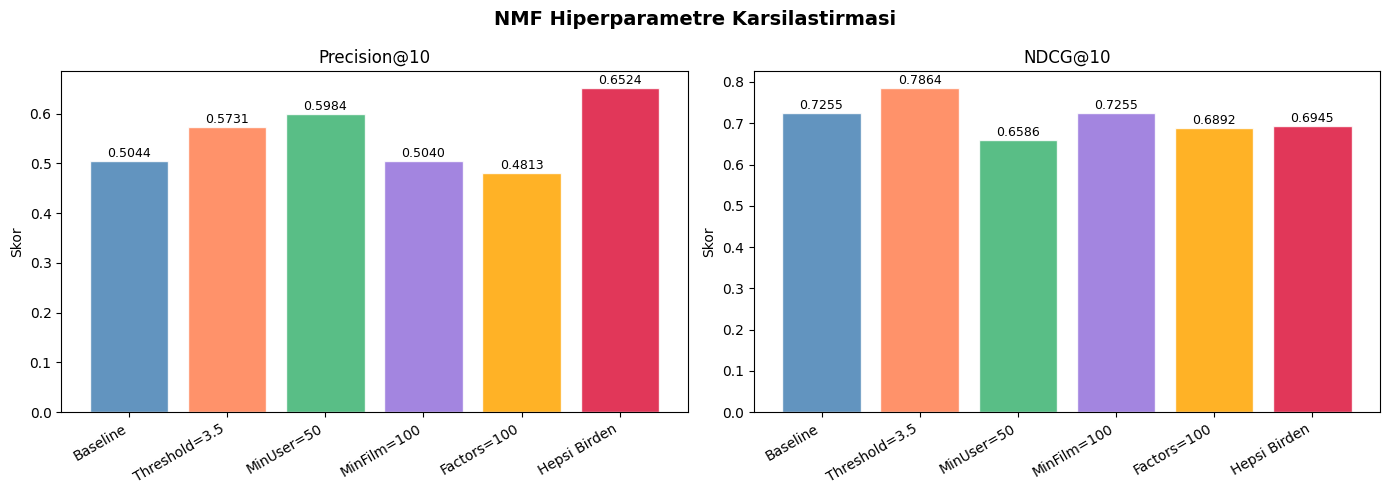

✅ Grafik kaydedildi!


In [7]:
# Grafik
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('NMF Hiperparametre Karsilastirmasi', fontsize=14, fontweight='bold')

metrics = ['Precision@10', 'NDCG@10']
colors  = ['steelblue', 'coral', 'mediumseagreen', 'mediumpurple', 'orange', 'crimson']

for ax, metric in zip(axes, metrics):
    vals   = results_df[metric]
    bars   = ax.bar(vals.index, vals.values, color=colors, alpha=0.85, edgecolor='white')
    ax.set_title(metric)
    ax.set_ylabel('Skor')
    ax.set_xticklabels(vals.index, rotation=30, ha='right')
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(r'C:\Users\Huseyin\Desktop\Movie_Lens\hiperparametre_karsilastirma.png', 
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ Grafik kaydedildi!')

In [8]:
result = run_nmf_experiment(
    ratings,
    min_movie_ratings = 50,
    min_user_ratings  = 50,
    threshold         = 3.5,
    n_factors         = 50,
    n_epochs          = 50
)
result['Deney'] = 'Threshold=3.5 + MinUser=50 + Epoch=50'

print('SONUC:')
for k, v in result.items():
    print(f'  {k}: {v}')

SONUC:
  min_movie_ratings: 50
  min_user_ratings: 50
  threshold: 3.5
  n_factors: 50
  n_epochs: 50
  Precision@10: 0.7682
  Recall@10: 0.5323
  NDCG@10: 0.837
  MAP: 0.745
  Sure(s): 316.8
  N_users: 85181
  Deney: Threshold=3.5 + MinUser=50 + Epoch=50


In [9]:
result = run_nmf_experiment(
    ratings,
    min_movie_ratings = 50,
    min_user_ratings  = 50,
    threshold         = 4,
    n_factors         = 50,
    n_epochs          = 50
)
result['Deney'] = 'Threshold=3.5 + MinUser=50 + Epoch=50'

print('SONUC:')
for k, v in result.items():
    print(f'  {k}: {v}')

SONUC:
  min_movie_ratings: 50
  min_user_ratings: 50
  threshold: 4
  n_factors: 50
  n_epochs: 50
  Precision@10: 0.6944
  Recall@10: 0.5514
  NDCG@10: 0.7814
  MAP: 0.6676
  Sure(s): 320.6
  N_users: 85115
  Deney: Threshold=3.5 + MinUser=50 + Epoch=50
